# 01: Pilot set inspection (E0)

Five iPhone photographs and five ChatGPT images: file properties, simple shortcut rules, and the same rules after normalisation (E0b).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import torch
print("GPU available:", torch.cuda.is_available())   # should print True

ROOT = "/content/drive/MyDrive/minor-project"

Mounted at /content/drive
GPU available: False


In [3]:
!pip install -q pillow-heif

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 20.5 MB/s eta 0:00:00


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ExifTags
from pillow_heif import register_heif_opener

register_heif_opener()

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".heic", ".heif"}


def describe(path):
    img = Image.open(path)
    arr = np.array(img)
    exif = img.getexif()

    camera = f"{exif.get(271, '')} {exif.get(272, '')}".strip() or "none"
    software = exif.get(305, "none")
    # 271 -> phone brand
    # 272 -> phone model
    # 305 -> software

    print(f"Format: {img.format} | Mode: {img.mode} | Size (W x H): {img.size[0]} x {img.size[1]}")
    print(f"As numbers: shape {arr.shape}, type {arr.dtype}, values from {arr.min()} to {arr.max()}")
    print(f"EXIF tags: {len(exif)} | Camera: {camera} | Software: {software}")
    print(f"Hidden extra info: {list(img.info.keys())}")

    return {
        "file": path.name,
        "format": img.format,
        "mode": img.mode,
        "width": img.size[0],
        "height": img.size[1],
        "file_kb": round(path.stat().st_size / 1024),
        "exif_tags": len(exif),
        "camera": camera,
    }


rows = []
for label in ["real", "fake"]:
    print(f"\n==================== {label.upper()} ====================")
    for path in sorted(Path(ROOT, "data", label).iterdir()):
        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        print(f"\n--- {path.name} ---")
        info = describe(path)
        info["label"] = label
        rows.append(info)

summary = pd.DataFrame(rows)
Path(ROOT, "results").mkdir(exist_ok=True)
summary.to_csv(Path(ROOT, "results", "01_data_inspection.csv"), index=False)
summary



==================== REAL ====================

--- IMG_6496.HEIC ---
Format: HEIF | Mode: RGB | Size (W x H): 4284 x 5712
As numbers: shape (5712, 4284, 3), type uint8, values from 0 to 255
EXIF tags: 11 | Camera: Apple iPhone 17 | Software: 26.4.1
Hidden extra info: ['primary', 'bit_depth', 'exif', 'metadata', 'thumbnails', 'depth_images', 'aux', 'tiling', 'chroma', 'icc_profile', 'icc_profile_type', 'entity_groups', 'original_orientation']

--- IMG_6770.HEIC ---
Format: HEIF | Mode: RGB | Size (W x H): 4284 x 5712
As numbers: shape (5712, 4284, 3), type uint8, values from 0 to 255
EXIF tags: 11 | Camera: Apple iPhone 17 | Software: 26.5
Hidden extra info: ['primary', 'bit_depth', 'exif', 'metadata', 'thumbnails', 'depth_images', 'aux', 'tiling', 'chroma', 'icc_profile', 'icc_profile_type', 'entity_groups', 'original_orientation']

--- IMG_6776.HEIC ---
Format: HEIF | Mode: RGB | Size (W x H): 4284 x 5712
As numbers: shape (5712, 4284, 3), type uint8, values from 0 to 255
EXIF tags:

,file,format,mode,width,height,file_kb,exif_tags,camera,label
0,IMG_6496.HEIC,HEIF,RGB,4284,5712,5631,11,Apple iPhone 17,real
1,IMG_6770.HEIC,HEIF,RGB,4284,5712,2404,11,Apple iPhone 17,real
2,IMG_6776.HEIC,HEIF,RGB,4284,5712,2583,11,Apple iPhone 17,real
3,IMG_6909.HEIC,HEIF,RGB,4284,5712,3218,11,Apple iPhone 17,real
4,IMG_7462.HEIC,HEIF,RGB,4284,5712,3818,11,Apple iPhone 17,real
5,creamy_pasta.png,PNG,RGB,512,512,379,0,none,fake
6,cute_kitten.png,PNG,RGB,512,512,329,0,none,fake
7,mountain_sunrise.png,PNG,RGB,768,512,479,0,none,fake
8,rainy_city_night.png,PNG,RGB,512,512,424,0,none,fake
9,sleeping_golden_retriever.png,PNG,RGB,768,512,524,0,none,fake


In [5]:
summary = pd.read_csv(Path(ROOT, "results", "01_data_inspection.csv"))

rules = {
    "file format is PNG": summary["format"] == "PNG",
    "width under 1000 pixels": summary["width"] < 1000,
    "file smaller than 1 MB": summary["file_kb"] < 1024,
    "no EXIF tags": summary["exif_tags"] == 0,
}

for name, says_fake in rules.items():
    prediction = np.where(says_fake, "fake", "real")
    accuracy = (prediction == summary["label"]).mean()
    print(f"Cheat rule '{name}': accuracy = {accuracy:.0%}")

Cheat rule 'file format is PNG': accuracy = 100%
Cheat rule 'width under 1000 pixels': accuracy = 100%
Cheat rule 'file smaller than 1 MB': accuracy = 100%
Cheat rule 'no EXIF tags': accuracy = 100%


In [9]:
from PIL import ImageOps

SIZE = 512
CLEAN = Path(ROOT, "data_clean")


def normalize(path, size=SIZE):
    img = Image.open(path)
    img = ImageOps.exif_transpose(img)
    img = img.convert("RGB")

    width, height = img.size
    if width < size or height < size:
        return None

    left = (width - size) // 2
    top = (height - size) // 2
    img = img.crop((left, top, left + size, top + size))
    return Image.fromarray(np.array(img))


for label in ["real", "fake"]:
    (CLEAN / label).mkdir(parents=True, exist_ok=True)
    for path in sorted(Path(ROOT, "data", label).iterdir()):
        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        clean = normalize(path)
        if clean is None:
            print(f"Skipped {path.name}: smaller than {SIZE} pixels")
            continue
        out_path = CLEAN / label / f"{path.stem}.png"
        clean.save(out_path)
        print(f"Saved {label}/{out_path.name}")


Saved real/IMG_6496.png
Saved real/IMG_6770.png
Saved real/IMG_6776.png
Saved real/IMG_6909.png
Saved real/IMG_7462.png
Saved fake/creamy_pasta.png
Saved fake/cute_kitten.png
Saved fake/mountain_sunrise.png
Saved fake/rainy_city_night.png
Saved fake/sleeping_golden_retriever.png


In [10]:
rows = []
for label in ["real", "fake"]:
    for path in sorted(Path(CLEAN, label).glob("*.png")):
        print(f"\n--- {label}/{path.name} ---")
        info = describe(path)
        info["label"] = label
        info["hidden_info"] = len(Image.open(path).info)
        rows.append(info)

clean_summary = pd.DataFrame(rows)
clean_summary.to_csv(Path(ROOT, "results", "02_clean_inspection.csv"), index=False)

rules = {
    "file format is PNG": clean_summary["format"] == "PNG",
    "width under 1000 pixels": clean_summary["width"] < 1000,
    "file smaller than 1 MB": clean_summary["file_kb"] < 1024,
    "no EXIF tags": clean_summary["exif_tags"] == 0,
    "no hidden info": clean_summary["hidden_info"] == 0,
}
print()
for name, says_fake in rules.items():
    prediction = np.where(says_fake, "fake", "real")
    accuracy = (prediction == clean_summary["label"]).mean()
    print(f"Cheat rule '{name}': accuracy = {accuracy:.0%}")



--- real/IMG_6496.png ---
Format: PNG | Mode: RGB | Size (W x H): 512 x 512
As numbers: shape (512, 512, 3), type uint8, values from 0 to 255
EXIF tags: 0 | Camera: none | Software: none
Hidden extra info: []

--- real/IMG_6770.png ---
Format: PNG | Mode: RGB | Size (W x H): 512 x 512
As numbers: shape (512, 512, 3), type uint8, values from 0 to 255
EXIF tags: 0 | Camera: none | Software: none
Hidden extra info: []

--- real/IMG_6776.png ---
Format: PNG | Mode: RGB | Size (W x H): 512 x 512
As numbers: shape (512, 512, 3), type uint8, values from 0 to 255
EXIF tags: 0 | Camera: none | Software: none
Hidden extra info: []

--- real/IMG_6909.png ---
Format: PNG | Mode: RGB | Size (W x H): 512 x 512
As numbers: shape (512, 512, 3), type uint8, values from 0 to 255
EXIF tags: 0 | Camera: none | Software: none
Hidden extra info: []

--- real/IMG_7462.png ---
Format: PNG | Mode: RGB | Size (W x H): 512 x 512
As numbers: shape (512, 512, 3), type uint8, values from 0 to 255
EXIF tags: 0 | Ca

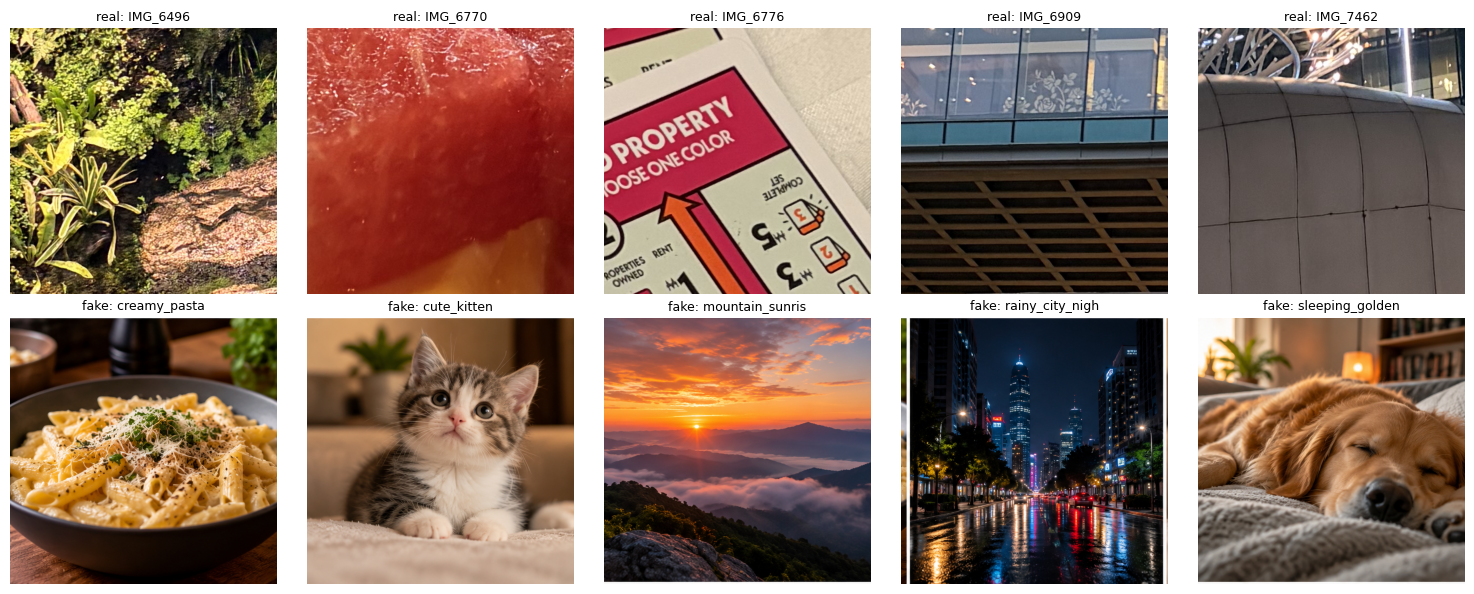

In [11]:
import matplotlib.pyplot as plt

paths = sorted(Path(CLEAN, "real").glob("*.png")) + sorted(Path(CLEAN, "fake").glob("*.png"))
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, path in zip(axes.flat, paths):
    ax.imshow(Image.open(path))
    ax.set_title(f"{path.parent.name}: {path.stem[:15]}", fontsize=9)
    ax.axis("off")
for ax in axes.flat[len(paths):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(Path(ROOT, "results", "02_clean_images.png"), dpi=100)
plt.show()


In [12]:
def check_rule(csv_name):
    table = pd.read_csv(Path(ROOT, "results", csv_name))

    check = table[["file", "format", "label"]].copy()
    check["rule_says"] = np.where(check["format"] == "PNG", "fake", "real")
    check["correct"] = check["rule_says"] == check["label"]
    display(check)

    n_correct = check["correct"].sum()
    n_total = len(check)
    print(f"Accuracy = {n_correct} correct / {n_total} images = {n_correct / n_total:.0%}\n")


print("BEFORE cleaning:")
check_rule("01_data_inspection.csv")

print("AFTER cleaning:")
check_rule("02_clean_inspection.csv")

BEFORE cleaning:


,file,format,label,rule_says,correct
0,IMG_6496.HEIC,HEIF,real,real,True
1,IMG_6770.HEIC,HEIF,real,real,True
2,IMG_6776.HEIC,HEIF,real,real,True
3,IMG_6909.HEIC,HEIF,real,real,True
4,IMG_7462.HEIC,HEIF,real,real,True
5,creamy_pasta.png,PNG,fake,fake,True
6,cute_kitten.png,PNG,fake,fake,True
7,mountain_sunrise.png,PNG,fake,fake,True
8,rainy_city_night.png,PNG,fake,fake,True
9,sleeping_golden_retriever.png,PNG,fake,fake,True


Accuracy = 10 correct / 10 images = 100%

AFTER cleaning:


,file,format,label,rule_says,correct
0,IMG_6496.png,PNG,real,fake,False
1,IMG_6770.png,PNG,real,fake,False
2,IMG_6776.png,PNG,real,fake,False
3,IMG_6909.png,PNG,real,fake,False
4,IMG_7462.png,PNG,real,fake,False
5,creamy_pasta.png,PNG,fake,fake,True
6,cute_kitten.png,PNG,fake,fake,True
7,mountain_sunrise.png,PNG,fake,fake,True
8,rainy_city_night.png,PNG,fake,fake,True
9,sleeping_golden_retriever.png,PNG,fake,fake,True


Accuracy = 5 correct / 10 images = 50%

